# French Motor Third-Party Liability Portfolio - Data Ingestion & SQL Pipeline

This notebook ingests the raw policy frequency and claim severity data from OpenML, loads them into DuckDB, runs the transformation scripts, and builds the Analytic Base Table (ABT).

In [1]:
import os
import sys
import yaml
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.data import load_config, ensure_directories, download_fremtpl2_data, build_duckdb_abt

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 1. Data Ingestion

In [2]:
config = load_config("../config/config.yaml")
nb_config = {
    "data": {
        "openml": config["data"]["openml"],
        "paths": {
            "raw_dir": "../data/raw",
            "processed_dir": "../data/processed",
            "database_dir": "../data/database",
            "duckdb_path": "../data/database/motor_portfolio.duckdb",
            "raw_freq_file": "../data/raw/freMTPL2freq.parquet",
            "raw_sev_file": "../data/raw/freMTPL2sev.parquet",
            "abt_file": "../data/processed/abt_motor_portfolio.parquet"
        }
    }
}

df_freq, df_sev = download_fremtpl2_data(nb_config)
print(f"Frequency records: {len(df_freq):,}")
print(f"Severity records: {len(df_sev):,}")

2026-10-06 17:55:08,167 [INFO] Loading cached raw datasets from ../data/raw


Frequency records: 678,013
Severity records: 26,639


## 2. DuckDB Schema Execution & ABT Generation

In [3]:
con = duckdb.connect(nb_config["data"]["paths"]["duckdb_path"])
con.register("df_freq_view", df_freq)
con.register("df_sev_view", df_sev)

with open("../sql/01_create_schema.sql", "r") as f:
    con.execute(f.read())
con.execute("INSERT INTO raw_freq SELECT * FROM df_freq_view")
con.execute("INSERT INTO raw_sev SELECT * FROM df_sev_view")

with open("../sql/02_aggregate_severity.sql", "r") as f:
    con.execute(f.read())

with open("../sql/03_build_abt.sql", "r") as f:
    con.execute(f.read())

df_abt = con.execute("SELECT * FROM abt_motor_portfolio").df()
df_abt.to_parquet(nb_config["data"]["paths"]["abt_file"], index=False)
print(f"ABT shape: {df_abt.shape}")

ABT shape: (678013, 22)


## 3. Portfolio Summary

In [4]:
summary_sql = """
SELECT
    COUNT(*) AS total_policies,
    ROUND(SUM(Exposure_Capped), 2) AS total_exposure_years,
    SUM(ClaimNb) AS total_claims,
    SUM(HasClaim) AS policies_with_claims,
    ROUND(SUM(ClaimNb) / SUM(Exposure_Capped) * 100, 3) AS claim_frequency_pct,
    ROUND(SUM(TotalClaimAmount), 2) AS total_losses_eur,
    ROUND(SUM(TotalClaimAmount) / SUM(Exposure_Capped), 2) AS empirical_pure_premium_eur
FROM abt_motor_portfolio;
"""
con.execute(summary_sql).df()

,total_policies,total_exposure_years,total_claims,policies_with_claims,claim_frequency_pct,total_losses_eur,empirical_pure_premium_eur
0,678013,358360.11,36102.0,34060.0,10.074,59909216.5,167.18


### Frequency by Driver Age

In [5]:
age_band_sql = """
SELECT
    CASE
        WHEN DrivAge < 25 THEN '18-24'
        WHEN DrivAge < 35 THEN '25-34'
        WHEN DrivAge < 50 THEN '35-49'
        WHEN DrivAge < 65 THEN '50-64'
        ELSE '65+'
    END AS DrivAgeBand,
    COUNT(*) AS PolicyCount,
    ROUND(SUM(Exposure_Capped), 1) AS TotalExposure,
    SUM(ClaimNb) AS TotalClaims,
    ROUND(SUM(ClaimNb) / SUM(Exposure_Capped) * 100, 2) AS FrequencyPct,
    ROUND(SUM(TotalClaimAmount) / NULLIF(SUM(Exposure_Capped), 0), 2) AS PurePremiumEUR
FROM abt_motor_portfolio
GROUP BY 1
ORDER BY MIN(DrivAge);
"""
df_age_summary = con.execute(age_band_sql).df()
df_age_summary

,DrivAgeBand,PolicyCount,TotalExposure,TotalClaims,FrequencyPct,PurePremiumEUR
0,18-24,30198,12488.9,2364.0,18.93,940.14
1,25-34,140947,64572.6,6396.0,9.91,154.21
2,35-49,252126,131168.7,12894.0,9.83,139.25
3,50-64,181580,102152.7,9888.0,9.68,130.06
4,65+,73162,47977.2,4560.0,9.50,138.79


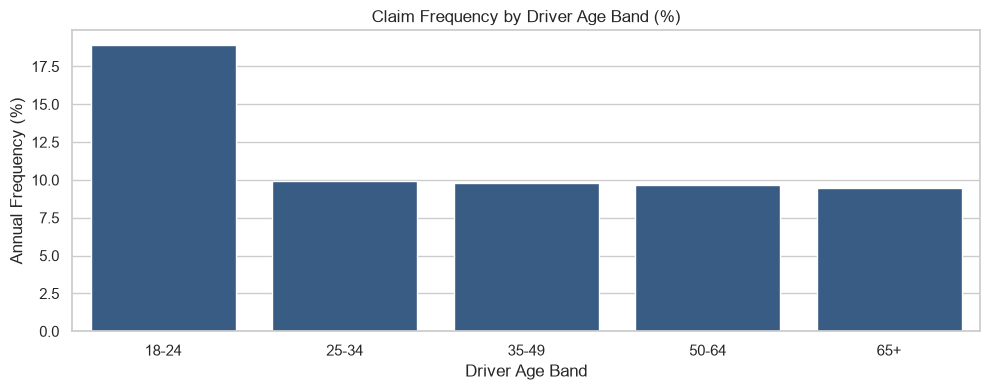

In [6]:
plt.figure(figsize=(10, 4))
sns.barplot(data=df_age_summary, x="DrivAgeBand", y="FrequencyPct", color="#2b5c8f")
plt.title("Claim Frequency by Driver Age Band (%)")
plt.ylabel("Annual Frequency (%)")
plt.xlabel("Driver Age Band")
plt.tight_layout()
plt.show()

### Frequency by Bonus-Malus

In [7]:
bm_sql = """
SELECT
    CASE
        WHEN BonusMalus = 50 THEN '50'
        WHEN BonusMalus < 70 THEN '51-69'
        WHEN BonusMalus < 100 THEN '70-99'
        WHEN BonusMalus = 100 THEN '100'
        ELSE '101+'
    END AS BonusMalusGroup,
    COUNT(*) AS Policies,
    ROUND(SUM(ClaimNb) / SUM(Exposure_Capped) * 100, 2) AS FrequencyPct,
    ROUND(SUM(TotalClaimAmount) / NULLIF(SUM(Exposure_Capped), 0), 2) AS PurePremiumEUR
FROM abt_motor_portfolio
GROUP BY 1
ORDER BY MIN(BonusMalus);
"""
df_bm_summary = con.execute(bm_sql).df()
df_bm_summary

,BonusMalusGroup,Policies,FrequencyPct,PurePremiumEUR
0,50,384156,8.02,98.97
1,51-69,150262,10.99,175.47
2,70-99,116271,13.87,240.74
3,100,19530,27.58,1632.41
4,101+,7794,37.58,716.92


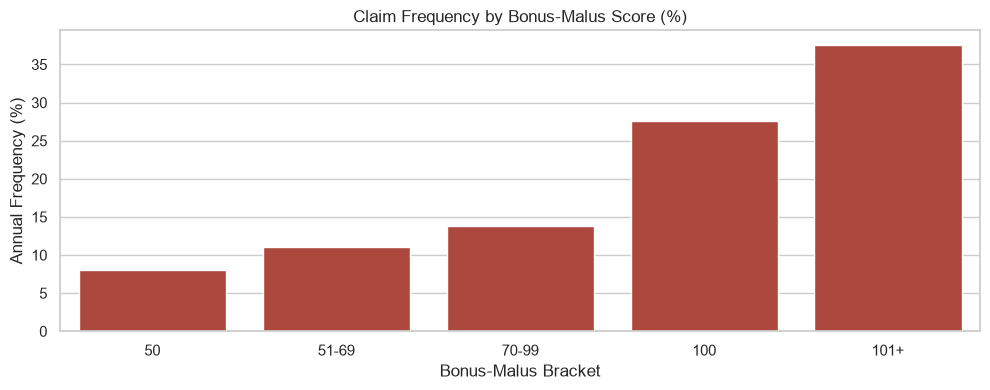

In [8]:
plt.figure(figsize=(10, 4))
sns.barplot(data=df_bm_summary, x="BonusMalusGroup", y="FrequencyPct", color="#c0392b")
plt.title("Claim Frequency by Bonus-Malus Score (%)")
plt.ylabel("Annual Frequency (%)")
plt.xlabel("Bonus-Malus Bracket")
plt.tight_layout()
plt.show()